NumPy mean: 3.0

Pandas data:
    Hours  Marks
0      1     35
1      2     40
2      3     50
3      4     55
4      5     65


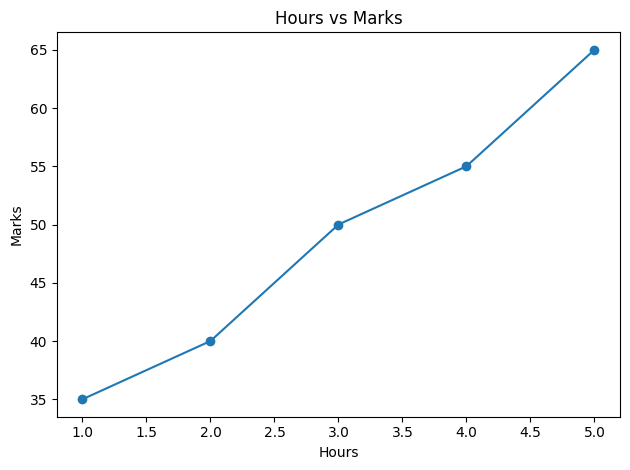

In [3]:
"""Practical 1: Python libraries for ML."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
arr = np.array([1, 2, 3, 4, 5])
df = pd.DataFrame({"Hours": [1,2,3,4,5], "Marks": [35,40,50,55,65]})
print("NumPy mean:", arr.mean())
print("\nPandas data:\n", df)
plt.plot(df["Hours"], df["Marks"], marker="o")
plt.xlabel("Hours"); plt.ylabel("Marks"); plt.title("Hours vs Marks")
plt.tight_layout(); plt.savefig("practical1_libraries.png")


In [4]:
"""Practical 2: Complete ML workflow with simple linear regression."""
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
data = {"Hours": [1,2,3,4,5,6,7,8], "Marks": [35,40,45,50,55,65,70,80]}
df = pd.DataFrame(data)
X, y = df[["Hours"]], df["Marks"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print("Dataset shape:", df.shape, "\nMissing values:\n", df.isnull().sum())
print("Slope:", model.coef_[0], "Intercept:", model.intercept_)
print("MSE:", mean_squared_error(y_test, pred), "R2:", r2_score(y_test, pred))
print("Predictions:", pred)


Dataset shape: (8, 2) 
Missing values:
 Hours    0
Marks    0
dtype: int64
Slope: 6.349999999999999 Intercept: 26.200000000000006
MSE: 0.8499999999999958 R2: 0.99456
Predictions: [38.9 64.3]


Degree 1: train MSE=11.849, test MSE=17.139, R2=0.815
Degree 2: train MSE=5.972, test MSE=6.409, R2=0.931
Degree 3: train MSE=3.264, test MSE=2.409, R2=0.974
Degree 10: train MSE=2.997, test MSE=3.269, R2=0.965


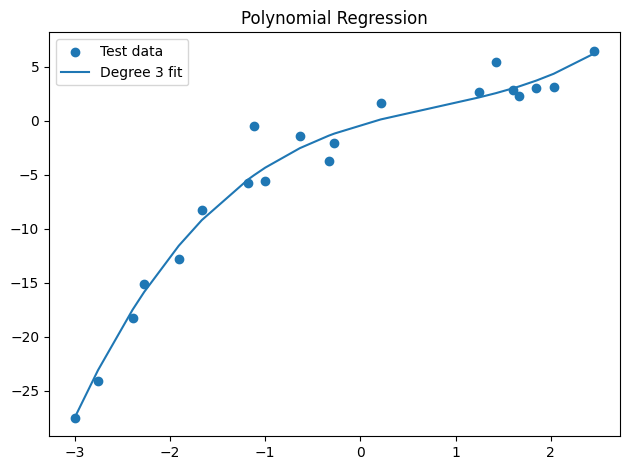

In [5]:
"""Practical 3: Bias, variance, overfitting and underfitting using polynomial regression."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = (0.5*X**3 - X**2 + 2*X + np.random.normal(0, 2, X.shape)).ravel()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
for degree in [1, 2, 3, 10]:
    poly = PolynomialFeatures(degree=degree)
    Xt, Xv = poly.fit_transform(X_train), poly.transform(X_test)
    model = LinearRegression().fit(Xt, y_train)
    train_mse = mean_squared_error(y_train, model.predict(Xt))
    test_pred = model.predict(Xv)
    print(f"Degree {degree}: train MSE={train_mse:.3f}, test MSE={mean_squared_error(y_test,test_pred):.3f}, R2={r2_score(y_test,test_pred):.3f}")
    if degree == 3:
        order = np.argsort(X_test[:,0])
        plt.scatter(X_test[:,0], y_test, label="Test data")
        plt.plot(X_test[order,0], test_pred[order], label="Degree 3 fit")
plt.legend(); plt.title("Polynomial Regression"); plt.tight_layout(); plt.savefig("practical3_polynomial.png")


Slope: 8187.76
Intercept: 24603.28
MAE: 2574.59
MSE: 7796907.40
R2: 0.986


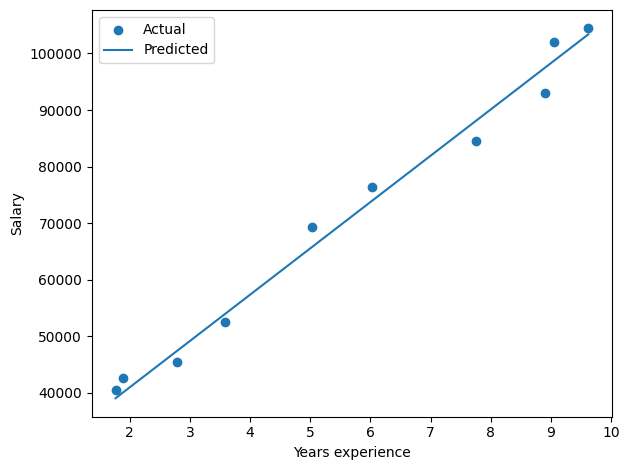

In [6]:
"""Practical 4: Simple linear regression for continuous prediction."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
np.random.seed(1)
experience = np.random.uniform(1, 10, 50)
salary = 25000 + experience*8000 + np.random.randn(50)*5000
X = experience.reshape(-1,1)
X_train, X_test, y_train, y_test = train_test_split(X, salary, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print(f"Slope: {model.coef_[0]:.2f}\nIntercept: {model.intercept_:.2f}")
print(f"MAE: {mean_absolute_error(y_test,pred):.2f}\nMSE: {mean_squared_error(y_test,pred):.2f}\nR2: {r2_score(y_test,pred):.3f}")
plt.scatter(X_test, y_test, label="Actual")
order=np.argsort(X_test[:,0]); plt.plot(X_test[order], pred[order], label="Predicted")
plt.xlabel("Years experience"); plt.ylabel("Salary"); plt.legend(); plt.tight_layout(); plt.savefig("practical4_linear_regression.png")


In [7]:
"""Practical 5: Multiple linear regression with multiple features."""
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
data=load_diabetes()
X_train,X_test,y_train,y_test=train_test_split(data.data,data.target,test_size=0.2,random_state=42)
model=LinearRegression().fit(X_train,y_train)
pred=model.predict(X_test)
print("Feature count:", X_train.shape[1])
print("MAE:", round(mean_absolute_error(y_test,pred),3))
print("MSE:", round(mean_squared_error(y_test,pred),3))
print("R2:", round(r2_score(y_test,pred),3))
print("First 5 predictions:", np.round(pred[:5],2))


Feature count: 10
MAE: 42.794
MSE: 2900.194
R2: 0.453
First 5 predictions: [139.55 179.52 134.04 291.42 123.79]


      Model      MSE  R2 Score
      Ridge 2892.015     0.454
      Lasso 2884.624     0.456
Elastic Net 2866.461     0.459


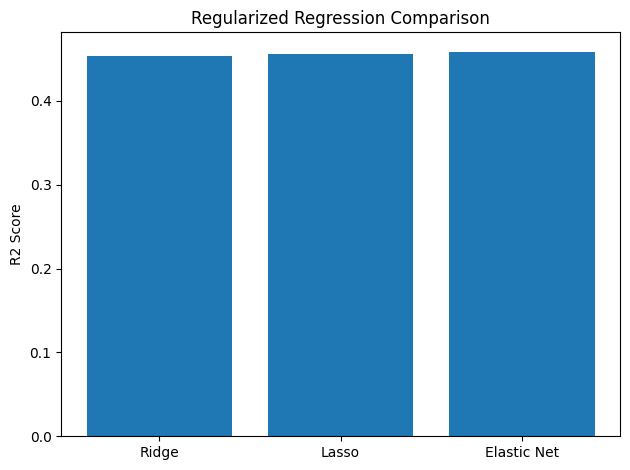

In [8]:
"""Practical 6: Ridge, Lasso and Elastic Net comparison."""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
data=load_diabetes()
X_train,X_test,y_train,y_test=train_test_split(data.data,data.target,test_size=0.2,random_state=42)
models={"Ridge":Ridge(alpha=1),"Lasso":Lasso(alpha=0.1),"Elastic Net":ElasticNet(alpha=0.1)}
rows=[]
for name,model in models.items():
    pipe=make_pipeline(StandardScaler(),model).fit(X_train,y_train)
    pred=pipe.predict(X_test)
    rows.append([name,mean_squared_error(y_test,pred),r2_score(y_test,pred)])
result=pd.DataFrame(rows,columns=["Model","MSE","R2 Score"])
print(result.round(3).to_string(index=False))
plt.bar(result["Model"],result["R2 Score"]); plt.ylabel("R2 Score"); plt.title("Regularized Regression Comparison")
plt.tight_layout(); plt.savefig("practical6_regularization.png")


Confusion matrix:
 [[41  1]
 [ 1 71]]
Accuracy: 0.9824561403508771
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



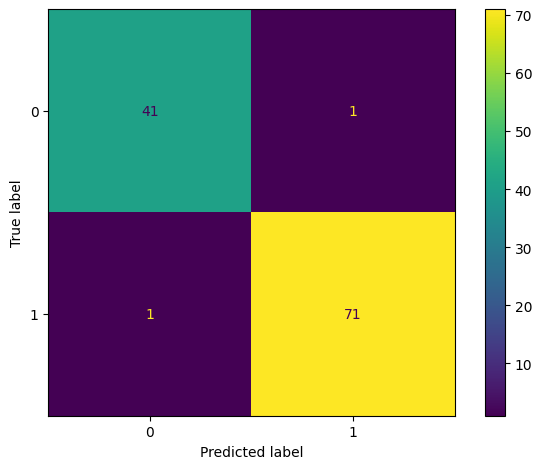

In [9]:
"""Practical 7: Logistic regression binary classification."""
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
data=load_breast_cancer()
X=pd.DataFrame(data.data,columns=data.feature_names); y=data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler(); X_train=scaler.fit_transform(X_train); X_test=scaler.transform(X_test)
model=LogisticRegression(max_iter=5000).fit(X_train,y_train)
pred=model.predict(X_test)
print("Confusion matrix:\n",confusion_matrix(y_test,pred))
print("Accuracy:",accuracy_score(y_test,pred))
print(classification_report(y_test,pred,target_names=data.target_names))
ConfusionMatrixDisplay.from_predictions(y_test,pred); plt.tight_layout(); plt.savefig("practical7_confusion_matrix.png")


In [10]:
"""Practical 8: K-nearest neighbors classification."""
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
data={"Brightness":[40,50,60,10,70,60,25],"Saturation":[20,50,90,25,70,10,80],"Class":["R","B","B","R","R","B","B"]}
df=pd.DataFrame(data)
X=df[["Brightness","Saturation"]]; y=df["Class"]
model=KNeighborsClassifier(n_neighbors=3).fit(X,y)
pred=model.predict(X)
print(df.to_string(index=False))
print("Training-set accuracy (illustrative only):",accuracy_score(y,pred))
print(classification_report(y,pred,zero_division=0))
print("New sample [55, 60] prediction:",model.predict([[55,60]])[0])


 Brightness  Saturation Class
         40          20     R
         50          50     B
         60          90     B
         10          25     R
         70          70     R
         60          10     B
         25          80     B
Training-set accuracy (illustrative only): 0.7142857142857143
              precision    recall  f1-score   support

           B       0.75      0.75      0.75         4
           R       0.67      0.67      0.67         3

    accuracy                           0.71         7
   macro avg       0.71      0.71      0.71         7
weighted avg       0.71      0.71      0.71         7

New sample [55, 60] prediction: B


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


Depth: 1, Accuracy: 0.67
Depth: 2, Accuracy: 0.93
Depth: 3, Accuracy: 0.97
Depth: 4, Accuracy: 0.93
Depth: 5, Accuracy: 0.93
Depth: 6, Accuracy: 0.93
Depth: 7, Accuracy: 0.93
Depth: 8, Accuracy: 0.93
Depth: 9, Accuracy: 0.93
Depth: 10, Accuracy: 0.93


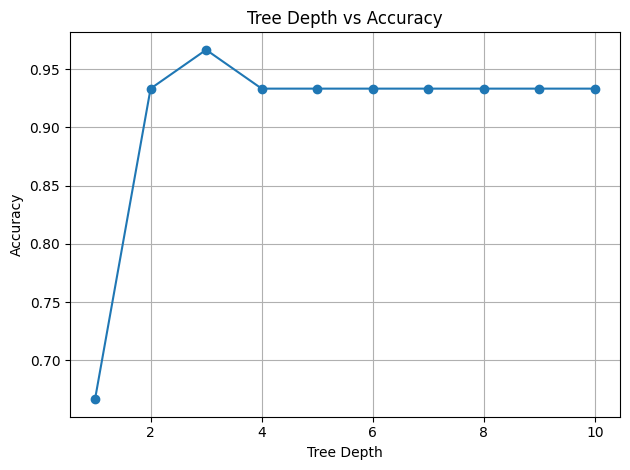

In [11]:
"""Practical 9: Decision tree depth and accuracy."""
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
data=load_iris(); X=data.data; y=data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
depth=range(1,11); accuracy=[]
for d in depth:
    model=DecisionTreeClassifier(max_depth=d,random_state=42).fit(X_train,y_train)
    acc=accuracy_score(y_test,model.predict(X_test)); accuracy.append(acc)
    print(f"Depth: {d}, Accuracy: {acc:.2f}")
plt.plot(list(depth),accuracy,marker="o"); plt.xlabel("Tree Depth"); plt.ylabel("Accuracy")
plt.title("Tree Depth vs Accuracy"); plt.grid(True); plt.tight_layout(); plt.savefig("practical9_tree_depth.png")


Decision Tree Accuracy: 0.9123
Random Forest Accuracy: 0.9561
Decision Tree 5-fold CV: 0.9173
Random Forest 5-fold CV: 0.9561


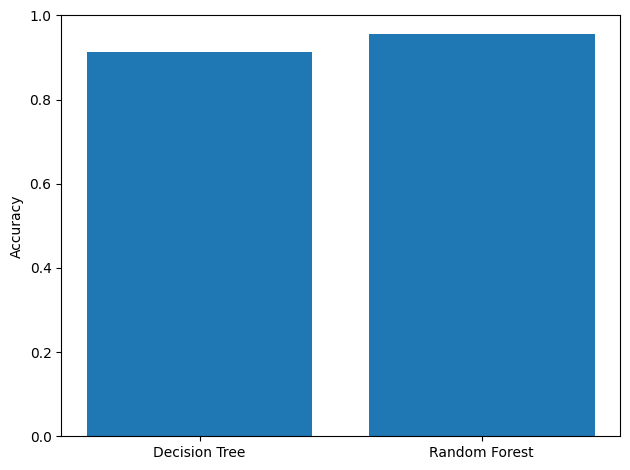

In [12]:
"""Practical 10: Random forest compared with a decision tree."""
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
data=load_breast_cancer(); X=data.data; y=data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
dt=DecisionTreeClassifier(random_state=42).fit(X_train,y_train)
rf=RandomForestClassifier(n_estimators=100,random_state=42).fit(X_train,y_train)
dt_acc=accuracy_score(y_test,dt.predict(X_test)); rf_acc=accuracy_score(y_test,rf.predict(X_test))
print(f"Decision Tree Accuracy: {dt_acc:.4f}")
print(f"Random Forest Accuracy: {rf_acc:.4f}")
print(f"Decision Tree 5-fold CV: {cross_val_score(DecisionTreeClassifier(random_state=42),X,y,cv=5).mean():.4f}")
print(f"Random Forest 5-fold CV: {cross_val_score(RandomForestClassifier(n_estimators=100,random_state=42),X,y,cv=5).mean():.4f}")
plt.bar(["Decision Tree","Random Forest"],[dt_acc,rf_acc]); plt.ylim(0,1); plt.ylabel("Accuracy")
plt.tight_layout(); plt.savefig("practical10_tree_forest.png")


K=1: WCSS=19780.25
K=2: WCSS=9211.21
K=3: WCSS=1919.36
K=4: WCSS=362.47
K=5: WCSS=329.27
K=6: WCSS=294.61
K=7: WCSS=261.56
K=8: WCSS=232.01
K=9: WCSS=209.10
K=10: WCSS=188.72


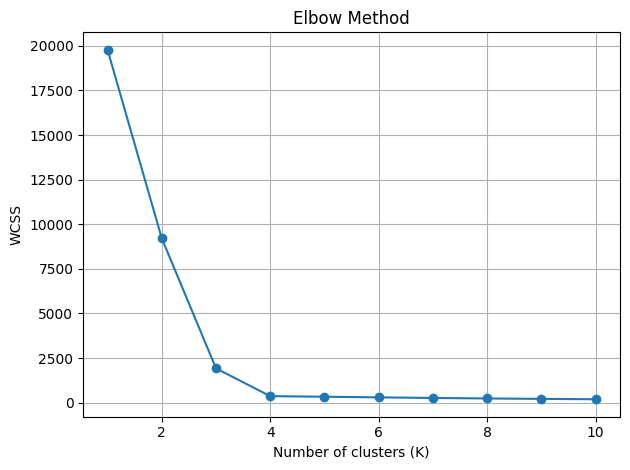

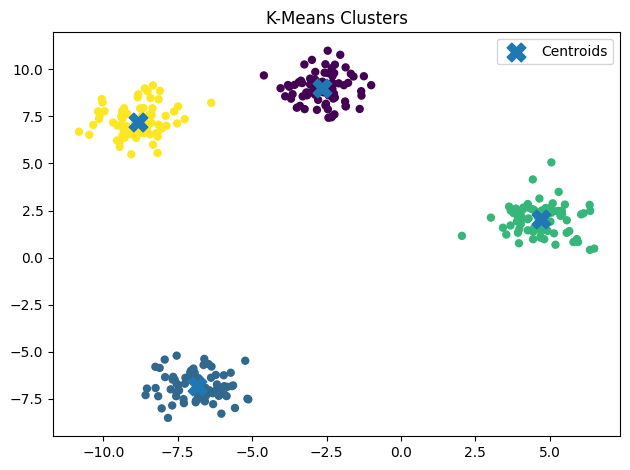

In [13]:
"""Practical 11: K-Means clustering and elbow method."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
X,_=make_blobs(n_samples=300,centers=4,cluster_std=0.8,random_state=42)
wcss=[]; k_range=range(1,11)
for k in k_range:
    model=KMeans(n_clusters=k,n_init=10,random_state=42).fit(X)
    wcss.append(model.inertia_); print(f"K={k}: WCSS={model.inertia_:.2f}")
plt.plot(list(k_range),wcss,marker="o"); plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS")
plt.title("Elbow Method"); plt.grid(True); plt.tight_layout(); plt.savefig("practical11_elbow.png")
final=KMeans(n_clusters=4,n_init=10,random_state=42).fit(X); labels=final.labels_
plt.figure(); plt.scatter(X[:,0],X[:,1],c=labels,s=25); plt.scatter(final.cluster_centers_[:,0],final.cluster_centers_[:,1],marker="X",s=180,label="Centroids")
plt.legend(); plt.title("K-Means Clusters"); plt.tight_layout(); plt.savefig("practical11_clusters.png")


Dataset shape: (150, 4)
Cluster sizes: {0: 64, 1: 50, 2: 36}


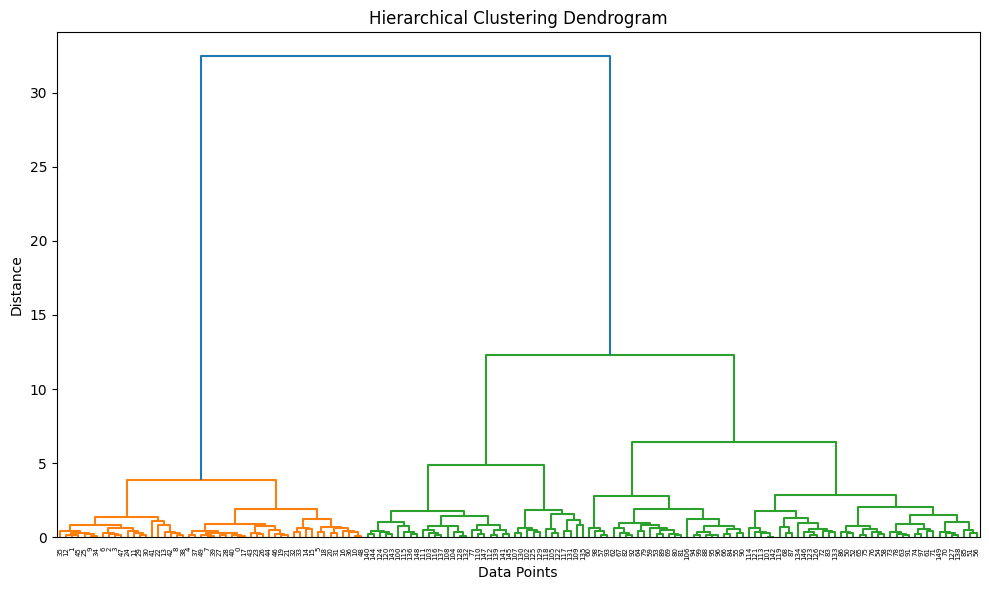

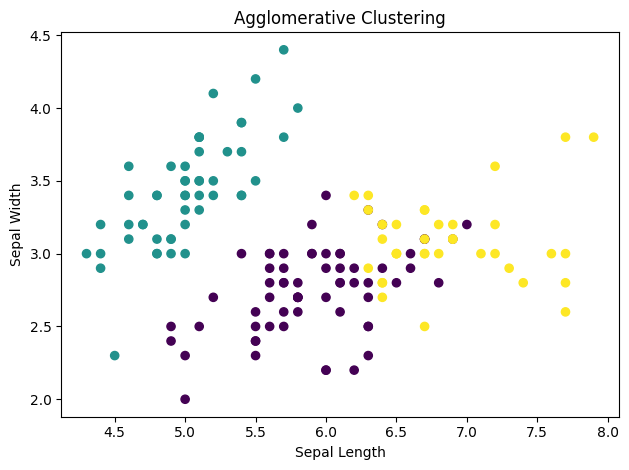

In [14]:
"""Practical 12: Agglomerative hierarchical clustering and dendrogram."""
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
iris=load_iris(); X=iris.data
print("Dataset shape:",X.shape)
linkage_matrix=linkage(X,method="ward")
plt.figure(figsize=(10,6)); dendrogram(linkage_matrix); plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points"); plt.ylabel("Distance"); plt.tight_layout(); plt.savefig("practical12_dendrogram.png")
model=AgglomerativeClustering(n_clusters=3,linkage="ward")
labels=model.fit_predict(X)
plt.figure(); plt.scatter(X[:,0],X[:,1],c=labels,s=35,cmap="viridis")
plt.xlabel("Sepal Length"); plt.ylabel("Sepal Width"); plt.title("Agglomerative Clustering")
plt.tight_layout(); plt.savefig("practical12_clusters.png")
print("Cluster sizes:",{int(i):int((labels==i).sum()) for i in set(labels)})


Number of clusters: 2
Number of noise points: 11


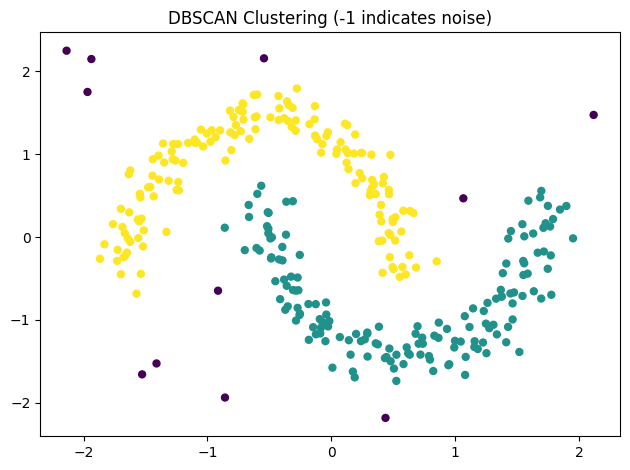

In [15]:
"""Practical 13: DBSCAN clustering and noise identification."""
import os
os.environ["OMP_NUM_THREADS"]="2"
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
X,_=make_moons(n_samples=300,noise=0.08,random_state=42)
np.random.seed(42)
noise_points=np.random.uniform(low=[-1.5,-1.0],high=[2.5,1.5],size=(20,2))
X=np.vstack([X,noise_points])
X_scaled=StandardScaler().fit_transform(X)
labels=DBSCAN(eps=0.25,min_samples=5).fit_predict(X_scaled)
n_clusters=len(set(labels))-(1 if -1 in labels else 0)
n_noise=int(np.sum(labels==-1))
print("Number of clusters:",n_clusters); print("Number of noise points:",n_noise)
plt.scatter(X_scaled[:,0],X_scaled[:,1],c=labels,cmap="viridis",s=25)
plt.title("DBSCAN Clustering (-1 indicates noise)"); plt.tight_layout(); plt.savefig("practical13_dbscan.png")


Dataset shape: (178, 13) Classes: 3
PC 1: 0.3620
PC 2: 0.1921
PC 3: 0.1112
PC 4: 0.0707
PC 5: 0.0656
PC 6: 0.0494
PC 7: 0.0424
PC 8: 0.0268
PC 9: 0.0222
PC 10: 0.0193
PC 11: 0.0174
PC 12: 0.0130
PC 13: 0.0080
Variance preserved by first 2 components: 55.41 %


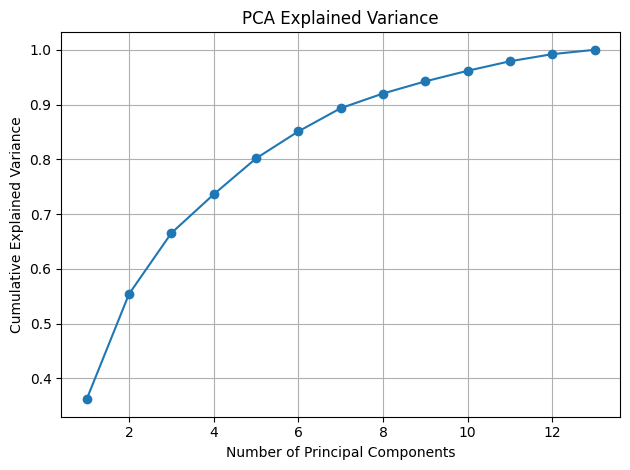

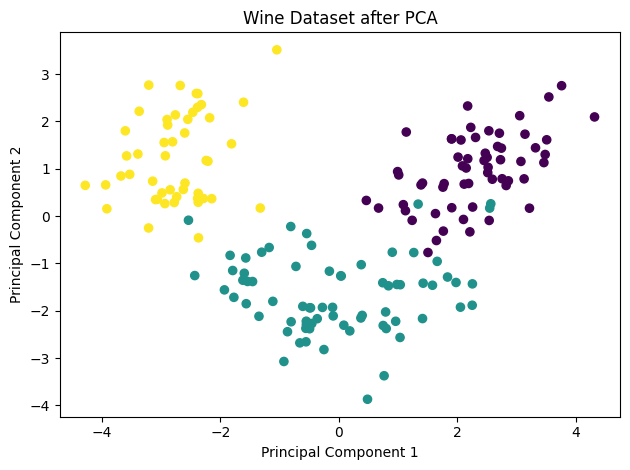

In [16]:
"""Practical 14: PCA dimensionality reduction on wine dataset."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
wine=load_wine(); X=wine.data; y=wine.target
X_scaled=StandardScaler().fit_transform(X)
pca=PCA().fit(X_scaled)
cum=np.cumsum(pca.explained_variance_ratio_)
print("Dataset shape:",X.shape,"Classes:",len(np.unique(y)))
for i,v in enumerate(pca.explained_variance_ratio_,1): print(f"PC {i}: {v:.4f}")
print("Variance preserved by first 2 components:",round(cum[1]*100,2),"%")
plt.plot(range(1,len(cum)+1),cum,marker="o"); plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance"); plt.title("PCA Explained Variance"); plt.grid(True)
plt.tight_layout(); plt.savefig("practical14_variance.png")
X2=PCA(n_components=2).fit_transform(X_scaled)
plt.figure(); plt.scatter(X2[:,0],X2[:,1],c=y,cmap="viridis",s=35)
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2"); plt.title("Wine Dataset after PCA")
plt.tight_layout(); plt.savefig("practical14_pca.png")


In [17]:
"""Practical 15: SVM hyperparameter tuning with grid search and cross-validation."""
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
iris=load_iris(); X=iris.data; y=iris.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model=SVC()
param_grid={"C":[0.1,1,10],"kernel":["linear","rbf"],"gamma":["scale","auto"]}
grid=GridSearchCV(model,param_grid,cv=5,scoring="accuracy")
grid.fit(X_train,y_train)
pred=grid.best_estimator_.predict(X_test)
print("Best parameters:",grid.best_params_)
print("Best cross-validation score:",round(grid.best_score_,4))
print("Test accuracy:",round(accuracy_score(y_test,pred),4))


Best parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best cross-validation score: 0.9833
Test accuracy: 0.9667
